# Example 3: I have a raw trace and want to see it next to its RQs

*An example for the `goldpan` / `goldsluice` note. Draft prepared with Claude Code for A. Villano, 2026-10-29.*

**The goal.** Take the pulses of a raw file, compute the quantities (RQs) with `goldsluice` on the spot, and draw one trace next to the numbers that describe it, with the numbers marked on the trace. Nothing is read from a processed file: the RQs are made here.

**The data here are made up.** `synthetic-goldpan/` holds the traces of 14 events (six sensors, 4096 samples each) in the native `goldpan` format, so the notebook runs on a fresh clone. A raw dump (idx) is read the same way: `adapters.read` guesses the format of the path, and a dump takes about 3 s to read in full.

Needs `goldpan` and `goldsluice` (both installed by `requirements.txt`). Run with the `darkmatter_cli_env` kernel.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from goldpan import adapters
import goldsluice

In [2]:
# The traces of the synthetic dump (rewritten from the generator if missing). For a raw dump: events = adapters.read("<dump folder>").
TRACES = Path("synthetic-goldpan")
if not TRACES.exists():
    _here = Path.cwd().resolve()
    REPO = next(p for p in [_here, *_here.parents] if (p / "python" / "tests" / "synthetic_series.py").exists())
    sys.path.insert(0, str(REPO / "python" / "tests"))
    import synthetic_series as ss
    ss.write_goldpan(ss.all_dumps()[0], TRACES)

events = adapters.read(TRACES)
config = events.detector.readout.segments[0].config      # pretrigger window, glitch samples, sample period: from the data, never assumed
print(events)
print(config)

Events(detector='NSDF', n_events=14, traces=[('Side2pA', 'main'), ('Side2pB', 'main'), ('Side2pC', 'main'), ('Side2pD', 'main'), ('Side2pE', 'main'), ('Side2pF', 'main')], quantities=['series', 'dump', 'event', 'trigger_type', 't_trigger'])
PulseConfig(pretrigger_samples=1000, glitch_samples=10, sample_period_s=8e-07)


In [3]:
# The RQs of one channel, for every event: goldsluice.run(<algorithm>, traces, **parameters) -> {quantity: one value per event}.
channel = "Side2pC"
traces = events.trace(channel).astype(float)                       # shape (events, samples)
window = dict(glitch_samples=config.glitch_samples, pretrigger_samples=config.pretrigger_samples)

rq = {}
rq.update(goldsluice.run("peak", traces, amps_per_adc=1.0, **window))           # adc_max, current_max (ADC counts)
rq.update(goldsluice.run("max_time", traces, sample_period_s=config.sample_period_s))
rq.update(goldsluice.run("baseline", traces, **window))
rq.update(goldsluice.run("excursion", traces, **window))
rq.update(goldsluice.run("integral", traces, sample_period_s=config.sample_period_s, **window))
rq.update(goldsluice.run("rise_time", traces, sample_period_s=config.sample_period_s, lo=0.1, hi=0.9, **window))

print(f"{len(traces)} events, {len(rq)} quantities:", list(rq))

14 events, 9 quantities: ['adc_max', 'current_max', 'max_time_s', 'baseline_mean', 'baseline_std', 'max_deviation', 'excursion_ratio', 'integral', 'rise_time_s']


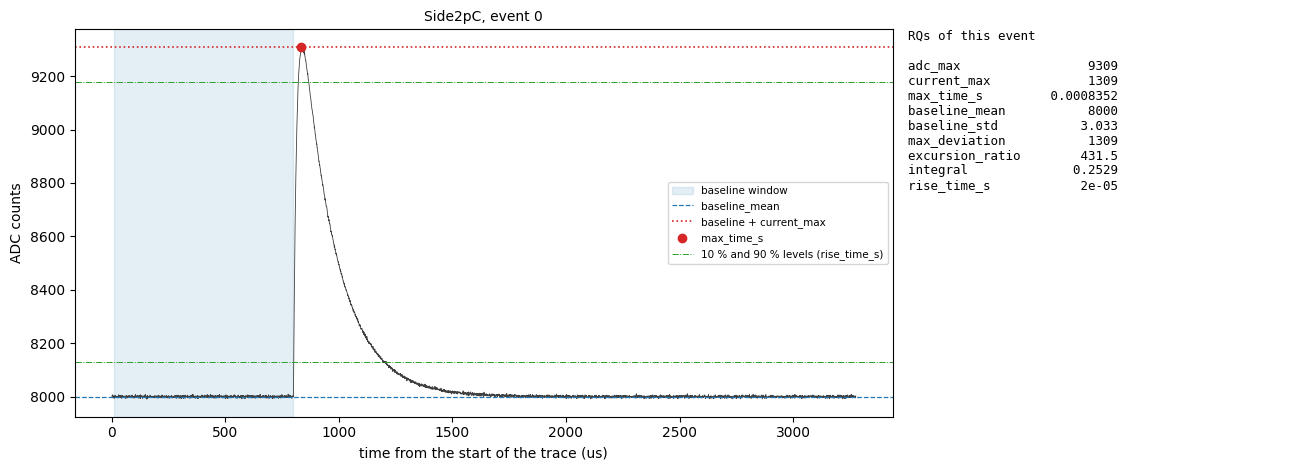

In [4]:
# One event, its trace on the left and its RQs on the right, each RQ marked on the trace.
i = int(np.argmax(rq["current_max"]))                              # the event with the largest pulse in this channel
trace = traces[i]
t_us = np.arange(len(trace)) * config.sample_period_s * 1e6
lo_s, hi_s = config.glitch_samples, config.pretrigger_samples      # the baseline window, in samples
base, std, peak = rq["baseline_mean"][i], rq["baseline_std"][i], rq["current_max"][i]

fig, (ax, axt) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw=dict(width_ratios=[2.2, 1]))
ax.plot(t_us, trace, lw=0.6, color="0.25")
ax.axvspan(t_us[lo_s], t_us[hi_s], color="C0", alpha=0.12, label="baseline window")
ax.axhline(base, color="C0", ls="--", lw=0.9, label="baseline_mean")
ax.axhline(base + peak, color="C3", ls=":", lw=1.2, label="baseline + current_max")
ax.plot(rq["max_time_s"][i] * 1e6, trace.max(), "o", color="C3", ms=6, label="max_time_s")
for frac in (0.1, 0.9):
    ax.axhline(base + frac * peak, color="C2", ls="-.", lw=0.7)
ax.plot([], [], color="C2", ls="-.", lw=0.7, label="10 % and 90 % levels (rise_time_s)")
ax.set_xlabel("time from the start of the trace (us)")
ax.set_ylabel("ADC counts")
ax.set_title(f"{channel}, event {i}", fontsize=10)
ax.legend(fontsize=7.5, loc="center right")

axt.axis("off")
rows = [f"{name:<16}{rq[name][i]:>12.4g}" for name in rq]
axt.text(0, 1, "RQs of this event" + chr(10) * 2 + chr(10).join(rows), va="top", family="monospace", fontsize=9)
fig.tight_layout()
plt.show()

**What this shows.** The RQs are short descriptions of the trace: the dashed line is `baseline_mean`, the dotted line sits at `baseline_mean + current_max`, the dot is at `max_time_s`, and the two thin lines are the 10 % and 90 % levels that `rise_time_s` is measured between. Each number in the table can be checked against the picture. `goldsluice.run` takes any array of traces of shape (events, samples), so the same cell works for any channel, or for the traces of a cut.

The `current_max` is in ADC counts: `amps_per_adc` is a placeholder equal to 1 until the ADC-to-amps scale is known.